In [1]:
!pip install -q datasets

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

In [3]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="foersben/mvtec-ad",
    repo_type="dataset",
    allow_patterns="bottle/*"
)

print("Dataset downloaded to:")
print(dataset_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 357 files:   0%|          | 0/357 [00:00<?, ?it/s]

Dataset downloaded to:
/root/.cache/huggingface/hub/datasets--foersben--mvtec-ad/snapshots/c75b39616f84db43677bcc8228caaafaf5096d7f


In [4]:
bottle_path = os.path.join(dataset_path, "bottle")

print("Bottle dataset:")
print(os.listdir(bottle_path))

Bottle dataset:
['readme.txt', 'test', 'license.txt', 'train', 'ground_truth']


In [5]:
train_path = os.path.join(
    bottle_path,
    "train",
    "good"
)

test_path = os.path.join(
    bottle_path,
    "test"
)

print("Training path:")
print(train_path)

print("\nTest path:")
print(test_path)

Training path:
/root/.cache/huggingface/hub/datasets--foersben--mvtec-ad/snapshots/c75b39616f84db43677bcc8228caaafaf5096d7f/bottle/train/good

Test path:
/root/.cache/huggingface/hub/datasets--foersben--mvtec-ad/snapshots/c75b39616f84db43677bcc8228caaafaf5096d7f/bottle/test


In [6]:
train_images = os.listdir(train_path)

print("Number of training images:", len(train_images))
print("First 5 images:", train_images[:5])

Number of training images: 209
First 5 images: ['126.png', '145.png', '106.png', '052.png', '171.png']


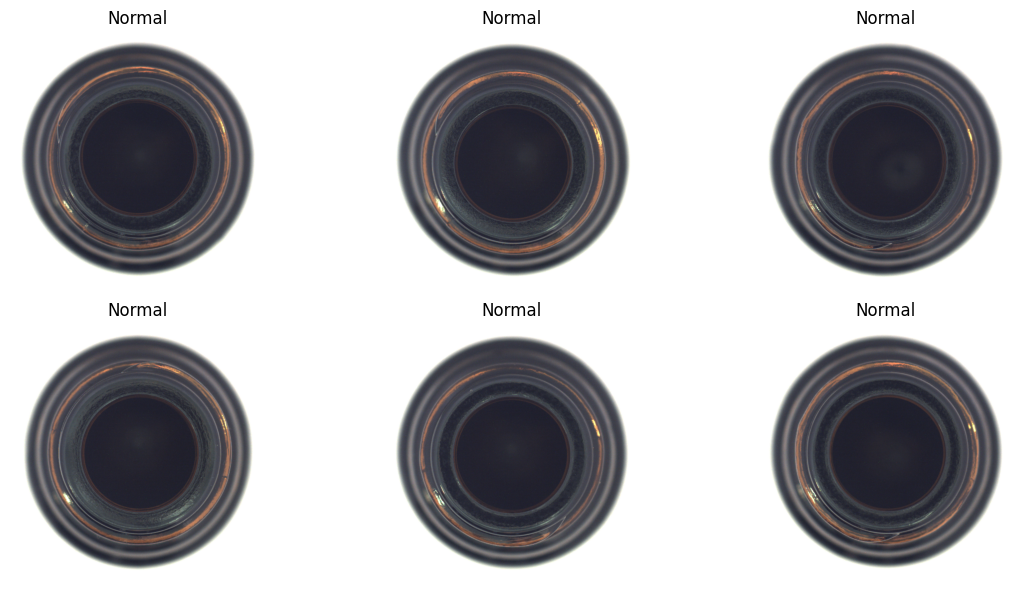

In [7]:
plt.figure(figsize=(12, 6))

for i in range(6):
    image_path = os.path.join(train_path, train_images[i])
    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title("Normal")

plt.tight_layout()
plt.show()

In [8]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [9]:
class NormalBottleDataset(Dataset):

    def __init__(self, folder, transform=None):
        self.folder = folder
        self.transform = transform

        self.images = [
            file for file in os.listdir(folder)
            if file.lower().endswith((".png", ".jpg", ".jpeg"))
        ]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        image_path = os.path.join(
            self.folder,
            self.images[index]
        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

In [10]:
train_dataset = NormalBottleDataset(
    train_path,
    transform=transform
)

print("Training images:", len(train_dataset))

Training images: 209


In [11]:
batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

print("Number of batches:", len(train_loader))

Number of batches: 14


In [12]:
class Autoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                128, 64,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                64, 32,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 3,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        encoded = self.encoder(x)

        decoded = self.decoder(encoded)

        return decoded

In [13]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = Autoencoder().to(device)

print(model)

Autoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(32, 3, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (5): Sigmoid()
  )
)


In [14]:
criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [15]:
epochs = 10

train_losses = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    for images in train_loader:

        images = images.to(device)

        # Forward pass
        outputs = model(images)

        # Reconstruction loss
        loss = criterion(outputs, images)

        # Clear old gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {epoch_loss:.6f}"
    )

Epoch [1/10] Loss: 0.115102
Epoch [2/10] Loss: 0.048204
Epoch [3/10] Loss: 0.017543
Epoch [4/10] Loss: 0.008802
Epoch [5/10] Loss: 0.006000
Epoch [6/10] Loss: 0.004347
Epoch [7/10] Loss: 0.003364
Epoch [8/10] Loss: 0.002722
Epoch [9/10] Loss: 0.002440
Epoch [10/10] Loss: 0.002307


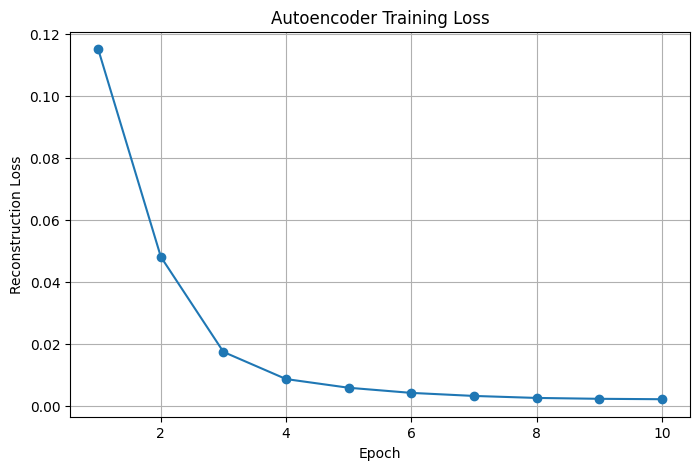

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("Autoencoder Training Loss")

plt.grid()
plt.show()

In [17]:
def reconstruction_error(model, image):

    model.eval()

    with torch.no_grad():
        image = image.to(device)

        reconstructed = model(image)

        error = torch.mean(
            (image - reconstructed) ** 2
        ).item()

    return error, reconstructed

In [18]:
normal_image_path = os.path.join(
    train_path,
    train_images[0]
)

normal_image = Image.open(normal_image_path).convert("RGB")

normal_tensor = transform(normal_image).unsqueeze(0)

error, reconstructed = reconstruction_error(
    model,
    normal_tensor
)

print("Reconstruction error:", error)

Reconstruction error: 0.0020922899711877108


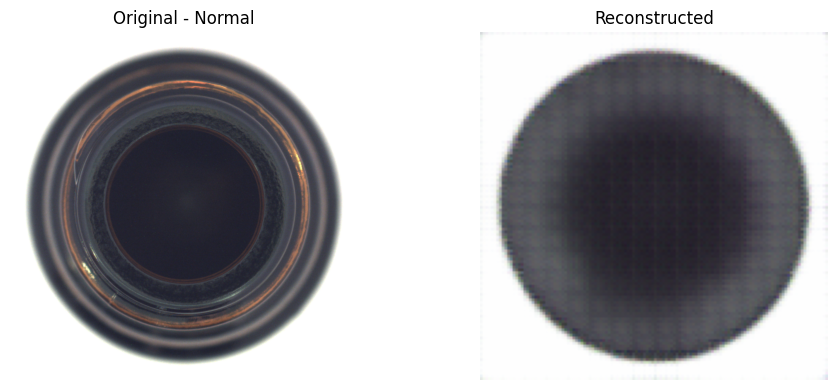

In [19]:
reconstructed_image = reconstructed.squeeze(0).cpu().permute(1, 2, 0).numpy()

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(normal_image)
plt.title("Original - Normal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_image)
plt.title("Reconstructed")
plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
test_categories = [
    folder for folder in os.listdir(test_path)
    if os.path.isdir(os.path.join(test_path, folder))
]

print(test_categories)

['good', 'broken_small', 'contamination', 'broken_large']


In [21]:
normal_test_path = os.path.join(
    test_path,
    "good"
)

normal_errors = []

normal_test_images = os.listdir(normal_test_path)

for filename in normal_test_images:

    image_path = os.path.join(
        normal_test_path,
        filename
    )

    image = Image.open(image_path).convert("RGB")

    image_tensor = transform(image).unsqueeze(0)

    error, _ = reconstruction_error(
        model,
        image_tensor
    )

    normal_errors.append(error)

print("Number of normal test images:", len(normal_errors))
print("Average normal error:", np.mean(normal_errors))

Number of normal test images: 20
Average normal error: 0.002486237435368821


In [22]:
anomaly_errors = []

anomaly_images = []

for category in test_categories:

    if category == "good":
        continue

    category_path = os.path.join(
        test_path,
        category
    )

    for filename in os.listdir(category_path):

        image_path = os.path.join(
            category_path,
            filename
        )

        image = Image.open(image_path).convert("RGB")

        image_tensor = transform(image).unsqueeze(0)

        error, _ = reconstruction_error(
            model,
            image_tensor
        )

        anomaly_errors.append(error)

        anomaly_images.append(
            (image_path, category)
        )

print("Number of anomalous images:", len(anomaly_errors))
print("Average anomaly error:", np.mean(anomaly_errors))

Number of anomalous images: 63
Average anomaly error: 0.0026591658085909865


Normal images
Mean error: 0.002486237435368821
Maximum error: 0.0030630978289991617

Anomalous images
Mean error: 0.0026591658085909865
Minimum error: 0.0015356290386989713


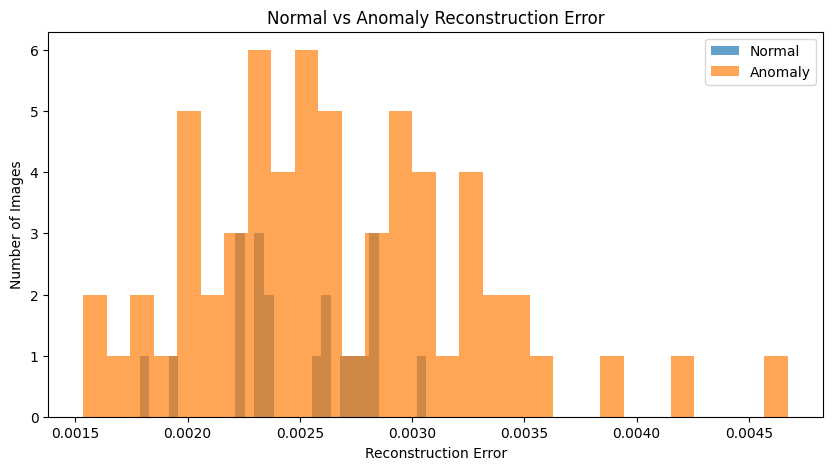

In [23]:
print("Normal images")
print("Mean error:", np.mean(normal_errors))
print("Maximum error:", np.max(normal_errors))

print("\nAnomalous images")
print("Mean error:", np.mean(anomaly_errors))
print("Minimum error:", np.min(anomaly_errors))



plt.figure(figsize=(10, 5))

plt.hist(
    normal_errors,
    bins=30,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    anomaly_errors,
    bins=30,
    alpha=0.7,
    label="Anomaly"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Normal vs Anomaly Reconstruction Error")

plt.legend()
plt.show()

In [24]:
train_errors = []

model.eval()

with torch.no_grad():

    for images in train_loader:

        images = images.to(device)

        reconstructed = model(images)

        errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=(1, 2, 3)
        )

        train_errors.extend(
            errors.cpu().numpy()
        )

print("Number of training errors:", len(train_errors))
print("Mean training error:", np.mean(train_errors))
print("Maximum training error:", np.max(train_errors))

Number of training errors: 209
Mean training error: 0.002248836
Maximum training error: 0.002910483


In [25]:
threshold = np.percentile(
    train_errors,
    95
)

print("Anomaly threshold:", threshold)

Anomaly threshold: 0.0027028953


In [26]:
normal_predictions = [
    0 if error <= threshold else 1
    for error in normal_errors
]

anomaly_predictions = [
    0 if error <= threshold else 1
    for error in anomaly_errors
]

print("Normal test images predicted as anomaly:",
      sum(normal_predictions))

print("Anomaly test images predicted as anomaly:",
      sum(anomaly_predictions))

Normal test images predicted as anomaly: 7
Anomaly test images predicted as anomaly: 26


In [27]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_true = (
    [0] * len(normal_errors)
    +
    [1] * len(anomaly_errors)
)

y_pred = (
    normal_predictions
    +
    anomaly_predictions
)

accuracy = accuracy_score(
    y_true,
    y_pred
)

print("Anomaly Detection Accuracy:",
      accuracy * 100, "%")

Anomaly Detection Accuracy: 46.98795180722892 %


[[13  7]
 [37 26]]


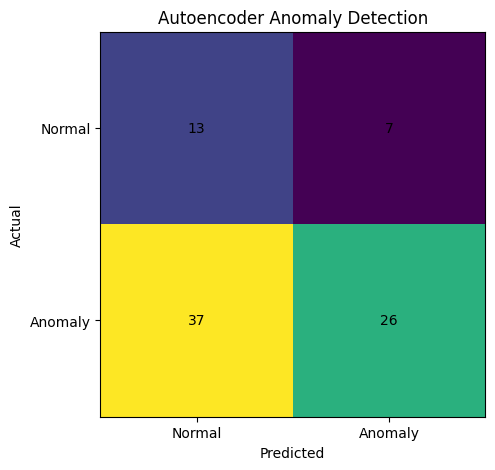

In [28]:
cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)


plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.xticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Autoencoder Anomaly Detection")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

In [29]:
class ImprovedAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(

            nn.Conv2d(3, 32, 3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 128, 3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 256, 3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                256, 128,
                3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.ConvTranspose2d(
                128, 64,
                3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.ConvTranspose2d(
                64, 32,
                3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 3,
                3,
                stride=2,
                padding=1,
                output_padding=1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        encoded = self.encoder(x)

        decoded = self.decoder(encoded)

        return decoded

In [30]:
model = ImprovedAutoencoder().to(device)

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

ImprovedAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=

In [31]:
epochs = 30

train_losses = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    for images in train_loader:

        images = images.to(device)

        outputs = model(images)

        loss = criterion(
            outputs,
            images
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = (
        running_loss /
        len(train_loader)
    )

    train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {epoch_loss:.6f}"
    )

Epoch [1/30] Loss: 0.098210
Epoch [2/30] Loss: 0.046960
Epoch [3/30] Loss: 0.025616
Epoch [4/30] Loss: 0.015563
Epoch [5/30] Loss: 0.010348
Epoch [6/30] Loss: 0.007300
Epoch [7/30] Loss: 0.005426
Epoch [8/30] Loss: 0.004237
Epoch [9/30] Loss: 0.003434
Epoch [10/30] Loss: 0.002859
Epoch [11/30] Loss: 0.002512
Epoch [12/30] Loss: 0.002241
Epoch [13/30] Loss: 0.001987
Epoch [14/30] Loss: 0.001741
Epoch [15/30] Loss: 0.001574
Epoch [16/30] Loss: 0.001492
Epoch [17/30] Loss: 0.001377
Epoch [18/30] Loss: 0.001241
Epoch [19/30] Loss: 0.001151
Epoch [20/30] Loss: 0.001085
Epoch [21/30] Loss: 0.001024
Epoch [22/30] Loss: 0.000941
Epoch [23/30] Loss: 0.000894
Epoch [24/30] Loss: 0.000846
Epoch [25/30] Loss: 0.000813
Epoch [26/30] Loss: 0.000783
Epoch [27/30] Loss: 0.000745
Epoch [28/30] Loss: 0.000726
Epoch [29/30] Loss: 0.000697
Epoch [30/30] Loss: 0.000675


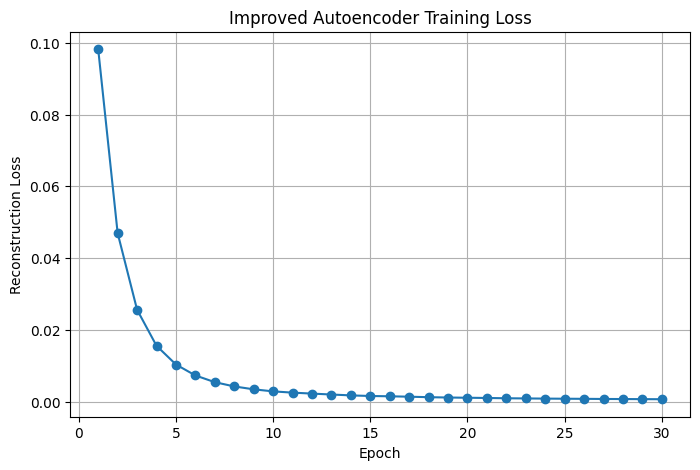

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("Improved Autoencoder Training Loss")

plt.grid()
plt.show()

In [33]:
train_errors = []

model.eval()

with torch.no_grad():

    for images in train_loader:

        images = images.to(device)

        reconstructed = model(images)

        errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=(1, 2, 3)
        )

        train_errors.extend(
            errors.cpu().numpy()
        )

print("Mean training error:",
      np.mean(train_errors))

print("Maximum training error:",
      np.max(train_errors))

Mean training error: 0.0006805507
Maximum training error: 0.0009087976


In [34]:
threshold = np.percentile(
    train_errors,
    95
)

print("New anomaly threshold:",
      threshold)

New anomaly threshold: 0.00081300846


In [35]:
normal_errors = []

for filename in normal_test_images:

    image_path = os.path.join(
        normal_test_path,
        filename
    )

    image = Image.open(
        image_path
    ).convert("RGB")

    image_tensor = transform(
        image
    ).unsqueeze(0)

    error, _ = reconstruction_error(
        model,
        image_tensor
    )

    normal_errors.append(error)

print("Normal mean error:",
      np.mean(normal_errors))

Normal mean error: 0.0007618774310685694


In [36]:
anomaly_errors = []

for category in test_categories:

    if category == "good":
        continue

    category_path = os.path.join(
        test_path,
        category
    )

    for filename in os.listdir(category_path):

        image_path = os.path.join(
            category_path,
            filename
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        image_tensor = transform(
            image
        ).unsqueeze(0)

        error, _ = reconstruction_error(
            model,
            image_tensor
        )

        anomaly_errors.append(error)

print("Anomaly mean error:",
      np.mean(anomaly_errors))

Anomaly mean error: 0.0010561831674302025


In [37]:
print("Normal")
print("Mean:", np.mean(normal_errors))
print("Maximum:", np.max(normal_errors))

print("\nAnomaly")
print("Mean:", np.mean(anomaly_errors))
print("Minimum:", np.min(anomaly_errors))

print("\nThreshold:", threshold)

Normal
Mean: 0.0007618774310685694
Maximum: 0.0009609485859982669

Anomaly
Mean: 0.0010561831674302025
Minimum: 0.0006368985050357878

Threshold: 0.00081300846


In [38]:
normal_predictions = [
    0 if error <= threshold else 1
    for error in normal_errors
]

anomaly_predictions = [
    0 if error <= threshold else 1
    for error in anomaly_errors
]

y_true = (
    [0] * len(normal_errors)
    +
    [1] * len(anomaly_errors)
)

y_pred = (
    normal_predictions
    +
    anomaly_predictions
)

accuracy = accuracy_score(
    y_true,
    y_pred
)

print(
    "Improved Anomaly Detection Accuracy:",
    accuracy * 100,
    "%"
)

Improved Anomaly Detection Accuracy: 78.3132530120482 %


[[16  4]
 [14 49]]


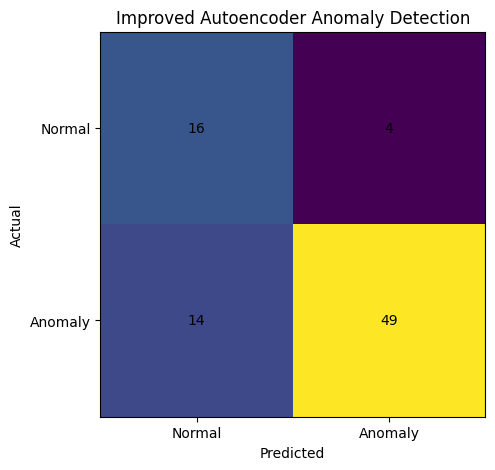

In [39]:
cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.xticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Anomaly"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Improved Autoencoder Anomaly Detection"
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

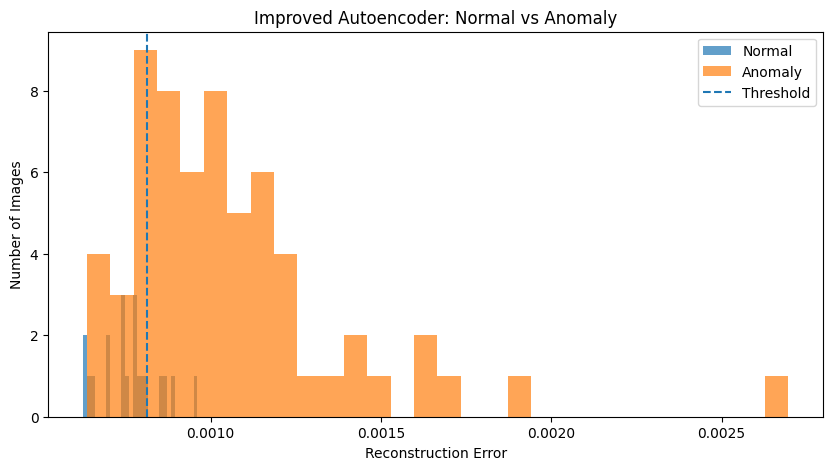

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(
    normal_errors,
    bins=30,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    anomaly_errors,
    bins=30,
    alpha=0.7,
    label="Anomaly"
)

plt.axvline(
    threshold,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title(
    "Improved Autoencoder: Normal vs Anomaly"
)

plt.legend()
plt.show()

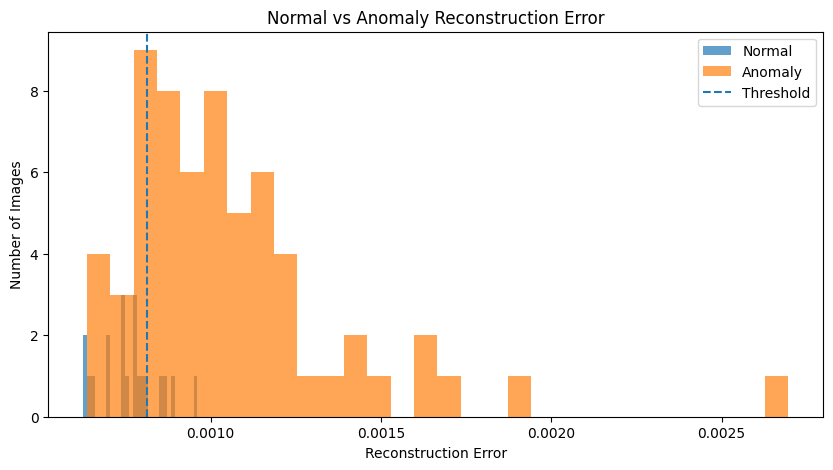

In [41]:
plt.figure(figsize=(10, 5))

plt.hist(normal_errors, bins=30, alpha=0.7, label="Normal")
plt.hist(anomaly_errors, bins=30, alpha=0.7, label="Anomaly")

plt.axvline(
    threshold,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Normal vs Anomaly Reconstruction Error")
plt.legend()
plt.show()

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# Reconstruction error itself is used as the anomaly score
scores = normal_errors + anomaly_errors

auc = roc_auc_score(y_true, scores)

print(f"Accuracy :  {accuracy:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-Score:   {f1:.4f}")
print(f"ROC-AUC:    {auc:.4f}")

Accuracy :  0.7831
Precision:  0.9245
Recall:     0.7778
F1-Score:   0.8448
ROC-AUC:    0.8611


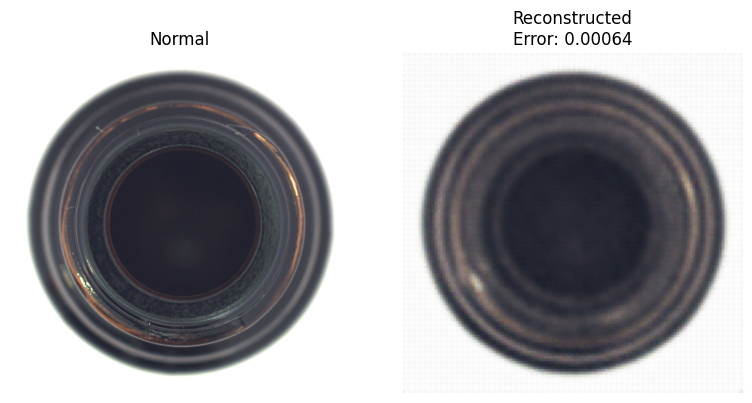

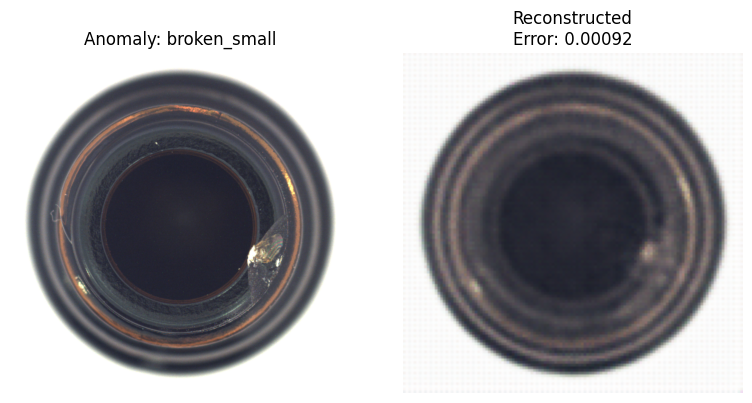

In [43]:
def show_reconstruction(image_path, title):

    image = Image.open(image_path).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        reconstructed = model(tensor)

    reconstructed = (
        reconstructed.squeeze(0)
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    error = torch.mean(
        (tensor.cpu() -
         torch.tensor(reconstructed).permute(2, 0, 1).unsqueeze(0)) ** 2
    ).item()

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(reconstructed)
    plt.title(f"Reconstructed\nError: {error:.5f}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# Normal example
show_reconstruction(
    os.path.join(normal_test_path, normal_test_images[0]),
    "Normal"
)

# Anomaly example
anomaly_path, anomaly_type = anomaly_images[0]

show_reconstruction(
    anomaly_path,
    f"Anomaly: {anomaly_type}"
)